In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pandas
import pickle

In [8]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
x = mnist.data.astype('float32') / 255.0  # Normalized (70000, 784)
y = mnist.target.astype('int')

In [9]:
w1 = np.random.normal(size=(7,7))    # the first filter
w2 = np.random.normal(size=(7,7))    # the second filter

In [11]:
def cross_correlation(x, w):
    return np.sum(x * w)

def convolution(x, w):
    fw = np.flipud(np.fliplr(w))    # flipped w
    return cross_correlation(x, fw)

def feat_map(x, w, s, method):
    rw, cw = w.shape
    rx, cx = x.shape
    rf = int((rx - rw) / s + 1)
    cf = int((cx - cw) / s + 1)
    feat = np.zeros(shape=(rf, cf))
    for i in range(rf):
        for j in range(cf):
            px = x[(i*s):(i*s+rw), (j*s):(j*s+cw)]
            if method == 'CROSS':
                feat[i, j] = cross_correlation(px, w)
            else:
                feat[i, j] = convolution(px, w)
    return np.maximum(0, feat)    # ReLU




Original image:


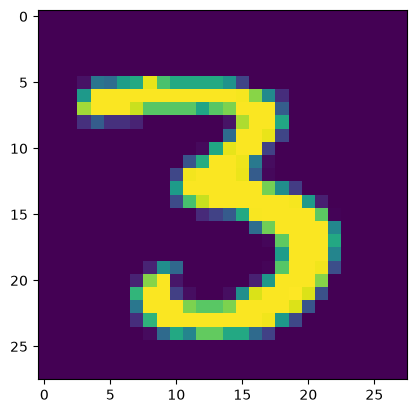

In [12]:
print("\nOriginal image:")
xi = x[12].reshape(28,28)
plt.imshow(xi)
plt.show()


Feature map by cross-correlation:


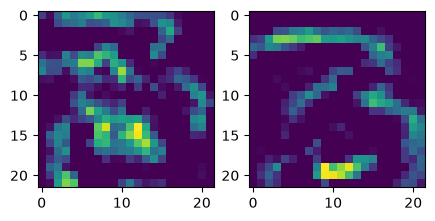

In [13]:
feat1 = feat_map(xi, w1, 1, 'CROSS')
feat2 = feat_map(xi, w2, 1, 'CROSS')
print("\nFeature map by cross-correlation:")
fig, ax = plt.subplots(1, 2, figsize=(5,5))
ax[0].imshow(feat1)
ax[1].imshow(feat2)
plt.show()


Feature map by convolution:


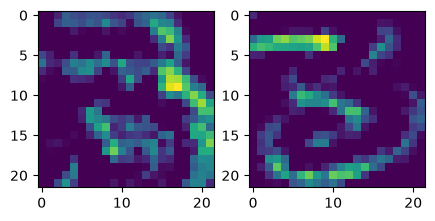

In [14]:
feat1 = feat_map(xi, w1, 1, 'CONV')
feat2 = feat_map(xi, w2, 1, 'CONV')
print("\nFeature map by convolution:")
fig, ax = plt.subplots(1, 2, figsize=(5,5))
ax[0].imshow(feat1)
ax[1].imshow(feat2)
plt.show()